# Aula 2 (assíncrona) - Parte A: notebook guiado

**Grandes Modelos de Linguagem · Residência em Engenharia de Software Inteligente (FACOM/UFMS)**
Prof. Bruno Nogueira · período: 05/11 a 18/11/2026 · atividade **individual** · cerca de 1h30

**Autor:** Arthur Bueno · **Grupo:** Arthur Bueno, Sueli Joboji, Henrique Chinaglia, André Kley

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bmnogueira-ufms/LLM-ESIA-2026/blob/main/aula02/aula02_notebook_guiado.ipynb)

Neste notebook você vai colocar a mão na massa com os conceitos da Aula 1:

| Exercício | Família / conceito | O que você vai fazer |
|---|---|---|
| 1 | Tokenização | comparar três tokenizadores em textos do **seu MVP** |
| 2 | Encoder-only | gerar embeddings com o BERTimbau, medir similaridade e treinar um classificador |
| 3 | Encoder-decoder | resumir um texto com um T5 em português |
| 4 | Decoder-only | fazer sua primeira chamada a um LLM e resolver **a mesma classificação** do exercício 2 em *zero-shot* |

As células marcadas com **✍️** pedem uma resposta curta sua. Elas vão alimentar a **ficha do caso de uso** (Parte B, em grupo).

> **Antes de começar:** *Ambiente de execução → Alterar o tipo de ambiente de execução → GPU T4*.
> **Versão adaptada ao caso de uso do grupo** — MVP: módulo *Inventário* do SGM (TJMS). Funcionalidade inteligente em análise: **classificar a observação em texto livre da digitação manual de patrimônio em um dos 5 motivos** (`etiqueta_danificada`, `etiqueta_ilegivel`, `plaqueta_impressa`, `plaqueta_gravada_material`, `outro`).
> Todos os textos e dados deste notebook são **sintéticos** (sem dados pessoais). O notebook original do professor está em `aula02/aula02_notebook_guiado.ipynb`.


## 0. Preparação

In [1]:
!pip install -q tiktoken openai

In [2]:
import time, re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import tiktoken
from transformers import AutoTokenizer, AutoModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("dispositivo:", device)

dispositivo: cuda


### Seus textos

Substitua os exemplos abaixo por **5 a 10 textos reais (ou realistas) do domínio do seu MVP** - mensagens de usuários, descrições, documentos curtos. **Não use dados pessoais ou sensíveis.**

In [3]:
TEXTOS_DO_MVP = [
    'A plaqueta do patrimônio está rasgada e o código de barras ficou cortado, o leitor não consegue ler.',
    'Número apagado pelo sol na plaqueta da janela, não dá para ler nem a olho nu.',
    'Etiqueta impressa em papel comum, sem código de barras, só o número escrito.',
    'Número gravado a punção na estrutura metálica da cadeira, não tem adesivo.',
    'O leitor de código de barras ficou sem bateria e a plaqueta estava perfeita.',
    'Plaqueta PJ 0098765 com o QR code riscado, a câmera do PWA não focou e digitei o número.',
    'Sem sinal de internet na sala da 3ª Vara, o PWA não abriu a câmera e digitei o número.',
    'Etiqueta de reposição impressa colada sobre a original, o leitor lê o código errado.',
]


---
## Exercício 1 - Tokenização

Compare três tokenizadores de famílias diferentes:
- **BERTimbau** (`neuralmind/bert-base-portuguese-cased`) - encoder-only, WordPiece, treinado em português;
- **GPT-4o** (`o200k_base`, via `tiktoken`) - decoder-only proprietário, BPE em bytes;
- **Qwen 2.5** (`Qwen/Qwen2.5-1.5B-Instruct`) - decoder-only aberto, BPE em bytes.

In [4]:
tok_bert = AutoTokenizer.from_pretrained("neuralmind/bert-base-portuguese-cased")
tok_qwen = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct")
enc_gpt4o = tiktoken.get_encoding("o200k_base")

def contar(texto):
    return {
        "BERTimbau": len(tok_bert(texto, add_special_tokens=False)["input_ids"]),
        "GPT-4o":    len(enc_gpt4o.encode(texto)),
        "Qwen2.5":   len(tok_qwen(texto, add_special_tokens=False)["input_ids"]),
    }

linhas = []
for t in TEXTOS_DO_MVP:
    c = contar(t)
    c["palavras"] = len(t.split())
    c["texto"] = t[:60] + ("…" if len(t) > 60 else "")
    linhas.append(c)
df_tok = pd.DataFrame(linhas)
df_tok

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

,BERTimbau,GPT-4o,Qwen2.5,palavras,texto
0,23,23,32,18,A plaqueta do patrimônio está rasgada e o códi...
1,22,20,24,16,"Número apagado pelo sol na plaqueta da janela,..."
2,18,17,21,13,"Etiqueta impressa em papel comum, sem código d..."
3,18,18,22,12,Número gravado a punção na estrutura metálica ...
4,17,16,23,14,O leitor de código de barras ficou sem bateria...
5,33,28,37,18,"Plaqueta PJ 0098765 com o QR code riscado, a c..."
6,25,25,32,19,"Sem sinal de internet na sala da 3ª Vara, o PW..."
7,21,19,23,14,Etiqueta de reposição impressa colada sobre a ...


{'BERTimbau': np.float64(1.43), 'GPT-4o': np.float64(1.34), 'Qwen2.5': np.float64(1.72)}


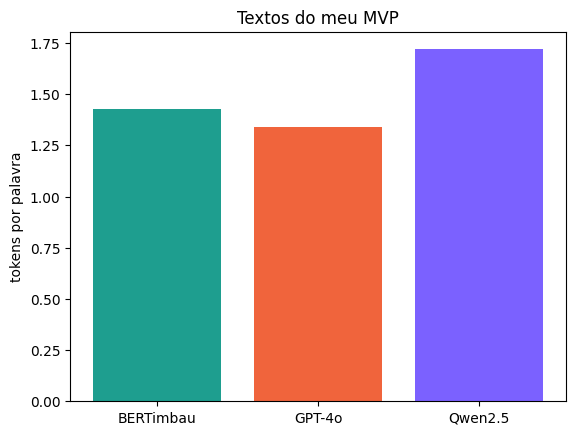

In [5]:
# Tokens por palavra, em média, para cada tokenizador
media = {nome: (df_tok[nome] / df_tok["palavras"]).mean() for nome in ["BERTimbau", "GPT-4o", "Qwen2.5"]}
print({k: round(v, 2) for k, v in media.items()})

plt.bar(media.keys(), media.values(), color=["#1E9E8F", "#F0643C", "#7B61FF"])
plt.ylabel("tokens por palavra")
plt.title("Textos do meu MVP")
plt.show()

In [6]:
# TODO: escolha o texto mais "difícil" da sua lista (siglas, nomes próprios, gírias, códigos)
# e veja como cada tokenizador o quebra.
texto = TEXTOS_DO_MVP[5]   # o mais difícil: sigla (PJ, PWA, QR) e número de patrimônio
print("BERTimbau:", tok_bert.tokenize(texto))
print("GPT-4o:   ", [enc_gpt4o.decode([i]) for i in enc_gpt4o.encode(texto)])
print("Qwen2.5:  ", [tok_qwen.decode([i]) for i in tok_qwen(texto, add_special_tokens=False)["input_ids"]])

BERTimbau: ['Pla', '##que', '##ta', 'P', '##J', '00', '##98', '##7', '##65', 'com', 'o', 'Q', '##R', 'cod', '##e', 'ris', '##cado', ',', 'a', 'câmera', 'do', 'P', '##WA', 'não', 'foco', '##u', 'e', 'dig', '##ite', '##i', 'o', 'número', '.']
GPT-4o:    ['Pla', 'queta', ' PJ', ' ', '009', '876', '5', ' com', ' o', ' QR', ' code', ' ris', 'cado', ',', ' a', ' câmera', ' do', ' P', 'WA', ' não', ' foc', 'ou', ' e', ' dig', 'itei', ' o', ' número', '.']
Qwen2.5:   ['Pl', 'aqu', 'eta', ' PJ', ' ', '0', '0', '9', '8', '7', '6', '5', ' com', ' o', ' QR', ' code', ' r', 'isc', 'ado', ',', ' a', ' câ', 'mer', 'a', ' do', ' P', 'WA', ' não', ' foc', 'ou', ' e', ' dig', 'ite', 'i', ' o', ' número', '.']


✍️ **Responda:** (a) Qual tokenizador foi mais econômico para os seus textos? (b) Quantos tokens tem, em média, uma entrada típica do seu MVP? (c) Algum termo importante do seu domínio foi muito fragmentado?

✍️ **Sua resposta:**

**(a)** O **GPT-4o** (`o200k_base`) foi o mais econômico: 1,34 tokens/palavra, contra 1,43 do BERTimbau e 1,72 do Qwen 2.5 (média nos 8 textos).

**(b)** Uma entrada típica (observação de 8 a 9 palavras, média do `conjunto_teste.csv`) tem **cerca de 13 tokens** (GPT-4o 13,0 · BERTimbau 13,3 · Qwen 15,6); máximo de 19 a 23 e p95 de 17 a 20. Nos 8 textos de exemplo, mais longos, ficam entre 17 e 33 tokens no BERTimbau.

**(c)** Sim, siglas e números. Em `PJ 0098765`, o Qwen gasta um token por dígito (`0 0 9 8 7 6 5`), o GPT-4o usa 3 blocos (`009 876 5`) e o BERTimbau 5 pedaços (`00 ##98 ##7 ##65`); `QR` vira `Q ##R` e `PWA` vira `P ##WA` no BERTimbau. A própria palavra central do domínio, **"plaqueta"**, é quebrada em 2 a 3 pedaços (`Pla ##que ##ta`). Para entradas curtas isso não pesa em custo, mas muda o que o modelo "vê".

---
## Exercício 2 - Encoder-only: embeddings e classificação com o BERTimbau

### 2.1 Similaridade semântica

Para ter **um vetor por frase**, tiramos a média dos vetores de todos os tokens (*mean pooling*), ignorando o *padding*.

In [7]:
bert = AutoModel.from_pretrained("neuralmind/bert-base-portuguese-cased").to(device).eval()

def embeddings(textos, batch=16):
    vetores = []
    for i in range(0, len(textos), batch):
        enc = tok_bert(textos[i:i + batch], padding=True, truncation=True, max_length=128, return_tensors="pt").to(device)
        with torch.no_grad():
            h = bert(**enc).last_hidden_state                  # (lote, tokens, 768)
        m = enc["attention_mask"].unsqueeze(-1).float()       # ignora [PAD]
        vetores.append(((h * m).sum(1) / m.sum(1)).cpu())
    v = torch.cat(vetores)
    return torch.nn.functional.normalize(v, dim=1).numpy()   # normalizado: produto interno = cosseno

frases = [
    "A plaqueta está rasgada.",
    "A etiqueta quebrou ao meio.",
    "O número está gravado no metal.",
    "O leitor está sem bateria.",
]
E = embeddings(frases)
pd.DataFrame(E @ E.T, index=frases, columns=[f"f{i+1}" for i in range(len(frases))]).round(3)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,f1,f2,f3,f4
A plaqueta está rasgada.,1.000,0.792,0.618,0.641
A etiqueta quebrou ao meio.,0.792,1.000,0.625,0.563
O número está gravado no metal.,0.618,0.625,1.000,0.676
O leitor está sem bateria.,0.641,0.563,0.676,1.000


> **Atenção:** o BERTimbau puro **não** foi treinado para similaridade de frases, então as similaridades tendem a ser todas altas. O que importa é a **ordem**: pares com o mesmo assunto devem ficar acima dos demais. Modelos treinados para isso (por exemplo, da biblioteca `sentence-transformers`) separam melhor - vamos usá-los no RAG da Aula 3.

In [8]:
# TODO: calcule a similaridade entre os textos do SEU MVP. Os pares mais parecidos fazem sentido?
E_mvp = embeddings(TEXTOS_DO_MVP)
pd.DataFrame(E_mvp @ E_mvp.T).round(3)

,0,1,2,3,4,5,6,7
0,1.000,0.805,0.772,0.635,0.842,0.740,0.733,0.767
1,0.805,1.000,0.711,0.668,0.701,0.706,0.758,0.674
2,0.772,0.711,1.000,0.735,0.778,0.691,0.631,0.808
3,0.635,0.668,0.735,1.000,0.629,0.613,0.589,0.706
4,0.842,0.701,0.778,0.629,1.000,0.756,0.698,0.754
5,0.740,0.706,0.691,0.613,0.756,1.000,0.808,0.688
6,0.733,0.758,0.631,0.589,0.698,0.808,1.000,0.583
7,0.767,0.674,0.808,0.706,0.754,0.688,0.583,1.000


### 2.2 Um classificador com embeddings

Aqui o conjunto são **60 observações sintéticas** de digitação manual na coleta do Inventário, em cinco motivos (12 por classe). Os embeddings do BERTimbau viram as *features* de uma regressão logística.

> Os dados estão embutidos na célula abaixo (colunas `texto` e `categoria`), então não é preciso baixar nem subir arquivos.

In [9]:
import io

DADOS_CSV = """texto,categoria
"Plaqueta rasgada no canto, o código de barras ficou cortado e o leitor não pega.",etiqueta_danificada
"Etiqueta amassada e com um pedaço faltando, digitei o número que sobrou legível.",etiqueta_danificada
"A plaqueta está quebrada ao meio, só consegui ler o número de uma das metades.",etiqueta_danificada
"Etiqueta descolando e dobrada, o código não fica plano para ler.",etiqueta_danificada
Plaqueta com risco profundo em cima do código de barras.,etiqueta_danificada
"Adesivo do patrimônio está queimado, provavelmente por estar perto de uma tomada.",etiqueta_danificada
A etiqueta foi arrancada pela metade quando mudaram a mesa de lugar.,etiqueta_danificada
"Plaqueta torta e rachada, o leitor não consegue focar.",etiqueta_danificada
Etiqueta com marca de umidade e parte do papel desfeita.,etiqueta_danificada
"Plaqueta de alumínio amassada, não dá para escanear.",etiqueta_danificada
"Etiqueta rasgada, mas deu para ver o numero inteiro a olho.",etiqueta_danificada
"Plaqueta partida no armário, achei o pedaço com o número.",etiqueta_danificada
"Número apagado pelo sol, não dá para ler o código nem a olho nu.",etiqueta_ilegivel
"A tinta da etiqueta desbotou, o leitor não reconhece as barras.",etiqueta_ilegivel
"Etiqueta suja de gordura, só consegui ler depois de limpar com cuidado.",etiqueta_ilegivel
"Código de barras borrado, tive que conferir os dígitos com a lupa do celular.",etiqueta_ilegivel
"Número muito apagado, fiquei em dúvida entre 3 e 8 no último dígito.",etiqueta_ilegivel
"Plaqueta desgastada pelo uso, os números quase sumiram.",etiqueta_ilegivel
"Etiqueta com tinta esmaecida, o leitor não lê e a câmera também não.",etiqueta_ilegivel
"Rasurada com caneta por alguém, difícil ler o número original.",etiqueta_ilegivel
"Barras sem contraste, parece que a impressão ficou fraca.",etiqueta_ilegivel
Número ilegível por causa de cola que vazou sobre a etiqueta.,etiqueta_ilegivel
"Caracteres apagados, consegui só pela foto ampliada.",etiqueta_ilegivel
Etiqueta lavada com produto de limpeza e o código sumiu.,etiqueta_ilegivel
"Plaqueta é de papel impresso a laser, o código de barras não é lido pelo leitor.",plaqueta_impressa
"Etiqueta impressa em impressora comum, sem código de barras, só o número.",plaqueta_impressa
"O patrimônio tem uma plaqueta impressa provisória, tive que digitar.",plaqueta_impressa
"Adesivo impresso na própria secretaria, o leitor não reconhece o formato.",plaqueta_impressa
"Plaqueta impressa em papel sulfite colada com fita, sem leitura por código.",plaqueta_impressa
A etiqueta impressa é de tamanho pequeno e o leitor não alcança.,plaqueta_impressa
"Bem com plaqueta impressa nova, mas o código não passa no leitor.",plaqueta_impressa
"Número só impresso, sem as barras.",plaqueta_impressa
"Etiqueta impressa em papel vegetal, o leitor falha.",plaqueta_impressa
"Plaqueta do tipo impressa, digitei o número que aparece embaixo.",plaqueta_impressa
"Tem uma etiqueta impressa de reposição, sem código de barras legível por máquina.",plaqueta_impressa
"Plaqueta impressa colada por cima da antiga, o leitor não lê.",plaqueta_impressa
"O número está gravado direto no metal da mesa, não tem etiqueta para ler.",plaqueta_gravada_material
Patrimônio gravado a punção na estrutura da cadeira.,plaqueta_gravada_material
Número gravado em baixo relevo na madeira do armário.,plaqueta_gravada_material
"Plaqueta gravada no material, sem código de barras, digitei o número.",plaqueta_gravada_material
"Gravação a laser no corpo do equipamento, o leitor não tem o que ler.",plaqueta_gravada_material
O número do bem está gravado na carcaça do computador.,plaqueta_gravada_material
Número esculpido na lateral do arquivo de aço.,plaqueta_gravada_material
"Identificação gravada no próprio móvel, não existe adesivo.",plaqueta_gravada_material
"Plaqueta de metal gravada, números em relevo, sem barras.",plaqueta_gravada_material
"Gravado na base do projetor, tive que virar o aparelho para ler.",plaqueta_gravada_material
"O patrimônio está gravado em ferro na estante, digitei o número.",plaqueta_gravada_material
Número marcado a fogo na madeira da mesa.,plaqueta_gravada_material
"Câmera do celular sem permissão, não consegui escanear.",outro
O leitor estava sem bateria e a plaqueta está em perfeito estado.,outro
"Bem está atrás de um armário pesado, só consegui enxergar o número de lado.",outro
"Sem sinal na sala, o aplicativo não carregou a câmera.",outro
Bem sem plaqueta; o servidor do setor informou o número do patrimônio.,outro
"Equipamento muito alto, na prateleira de cima, não alcancei para escanear.",outro
"Etiqueta colocada em local de difícil acesso, dentro da gaveta fixa.",outro
"O leitor travou depois de algumas leituras, reiniciei e digitei o restante.",outro
"Estou com pressa porque a sala será fechada, digitei os últimos itens.",outro
"Plaqueta caiu e estava solta em cima da mesa, associei ao bem.",outro
"Celular com a tela quebrada, difícil de usar a câmera.",outro
"Não sei, digitei por engano antes de tentar ler.",outro
"""
df = pd.read_csv(io.StringIO(DADOS_CSV))
print(df["categoria"].value_counts())
df.sample(5, random_state=0)


categoria
etiqueta_danificada          12
etiqueta_ilegivel            12
plaqueta_impressa            12
plaqueta_gravada_material    12
outro                        12
Name: count, dtype: int64


,texto,categoria
26,O patrimônio tem uma plaqueta impressa provisó...,plaqueta_impressa
35,"Plaqueta impressa colada por cima da antiga, o...",plaqueta_impressa
59,"Não sei, digitei por engano antes de tentar ler.",outro
28,Plaqueta impressa em papel sulfite colada com ...,plaqueta_impressa
11,"Plaqueta partida no armário, achei o pedaço co...",etiqueta_danificada


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

treino, teste = train_test_split(df, test_size=20, stratify=df["categoria"], random_state=42)

inicio = time.time()
X_treino, X_teste = embeddings(treino["texto"].tolist()), embeddings(teste["texto"].tolist())
clf = LogisticRegression(max_iter=2000).fit(X_treino, treino["categoria"])
pred_bert = clf.predict(X_teste)
tempo_bert = (time.time() - inicio) / len(df)

acc_bert = accuracy_score(teste["categoria"], pred_bert)
print(f"Acurácia BERTimbau + regressão logística: {acc_bert:.0%}  (tempo médio por exemplo: {1000 * tempo_bert:.0f} ms)")
print(classification_report(teste["categoria"], pred_bert, zero_division=0))

Acurácia BERTimbau + regressão logística: 55%  (tempo médio por exemplo: 4 ms)
                           precision    recall  f1-score   support

      etiqueta_danificada       0.25      0.25      0.25         4
        etiqueta_ilegivel       0.50      0.25      0.33         4
                    outro       1.00      0.75      0.86         4
plaqueta_gravada_material       1.00      0.50      0.67         4
        plaqueta_impressa       0.44      1.00      0.62         4

                 accuracy                           0.55        20
                macro avg       0.64      0.55      0.54        20
             weighted avg       0.64      0.55      0.54        20



✍️ **Responda:** Quantos exemplos rotulados foram usados no treino? Em quais categorias o classificador mais errou? Você acha que esse desempenho seria aceitável no seu MVP?

✍️ **Sua resposta:**

Foram usados **40 exemplos rotulados** no treino (60 menos 20 de teste). A acurácia no teste foi de **55%** (11/20). Os maiores erros foram em `etiqueta_danificada` (F1 0,25) e `etiqueta_ilegivel` (recall 0,25): as duas descrevem o mesmo cenário físico (plaqueta ruim) e o modelo as confunde; `plaqueta_impressa` teve recall 1,0 mas precisão 0,44 (vira "lixeira"). `outro` (F1 0,86) e `plaqueta_gravada_material` (0,67) foram as melhores. Com os 60 exemplos e testando nos 25 do grupo, a acurácia sobe para **72%**, mas cai a **38% nos casos difíceis**. Sozinho, **não** seria aceitável: serve como triagem barata (4 a 7 ms por exemplo na T4), não como decisão final.

---
## Exercício 3 - Encoder-decoder: sumarização com um T5 em português

Modelo: `recogna-nlp/ptt5-base-summ-xlsum` - um PTT5 (T5 pré-treinado em português) ajustado para resumir notícias.

> ⚠️ Verifique sempre a **licença** do modelo. Este é distribuído sob **CC BY-NC-SA 4.0**, que **não permite uso comercial**. Isso é uma restrição real para um MVP!

In [11]:
from transformers import AutoModelForSeq2SeqLM

tok_t5 = AutoTokenizer.from_pretrained("recogna-nlp/ptt5-base-summ-xlsum")
t5 = AutoModelForSeq2SeqLM.from_pretrained("recogna-nlp/ptt5-base-summ-xlsum").to(device)

def resumir(texto, max_new_tokens=60):
    enc = tok_t5(texto, max_length=512, truncation=True, return_tensors="pt").to(device)
    with torch.no_grad():
        out = t5.generate(**enc, max_new_tokens=max_new_tokens, num_beams=4, no_repeat_ngram_size=3)
    return tok_t5.decode(out[0], skip_special_tokens=True)

noticia = (
    "A prefeitura de uma capital do Centro-Oeste anunciou nesta segunda-feira um programa para ampliar o acesso à internet "
    "em escolas públicas. Segundo a secretaria de educação, 120 escolas receberão novos pontos de acesso sem fio até o fim "
    "do ano, e os professores participarão de oficinas sobre o uso de ferramentas digitais em sala de aula. O investimento "
    "previsto é de 8 milhões de reais, com recursos municipais e federais."
)   # texto fictício
print(resumir(noticia))

config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  756kB            

spiece.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/1.79k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  892MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

Professores de escolas públicas do Centro-Oeste da cidade de São Paulo vão receber gratuitamente acesso à internet em sala de aula.


In [12]:
relatorio = (
    "Na coleta do espaço físico 2005, a equipe registrou 132 bens, dos quais 9 foram digitados manualmente. "
    "Entre as digitações, 4 tiveram como motivo plaqueta danificada, 3 plaqueta ilegível e 2 outro motivo. "
    "Dois bens foram marcados como divergentes porque a descrição encontrada difere da cadastrada. "
    "O gestor aprovou 7 das 9 pendências e rejeitou 2 por falta de foto da plaqueta. "
    "A coordenadoria deve reabrir o espaço caso novas leituras sejam necessárias."
)   # texto fictício, números inventados
print(resumir(relatorio))


A equipe de pesquisadores do Instituto de Pesquisa Econômica Aplicada (Ipea, na sigla em inglês) divulgou nesta quarta-feira uma série de imagens de objetos e pessoas que, segundo eles, teriam sido digitados ilegalmente.


✍️ **Responda:** O resumo manteve as informações principais? Inventou algo que não estava no texto (alucinação)? Uma tarefa de "transformar texto" aparece no seu MVP?

✍️ **Sua resposta:**

O resumo da notícia de exemplo **inventou** informação: "Professores de escolas públicas do Centro-Oeste da *cidade de São Paulo* vão receber *gratuitamente* acesso à internet" (o texto fala de uma capital do Centro-Oeste, 120 escolas e sem menção a gratuidade). Com o relatório fictício de coleta, o resultado foi **alucinação completa**: falou do Ipea e de "objetos e pessoas digitados ilegalmente", sem relação com o texto. Há uma tarefa de "transformar texto" no MVP (resumir o histórico de pendências de um espaço para o aprovador ou a coordenadoria), mas este modelo **não serve**: alucina e tem licença CC BY-NC-SA 4.0 (sem uso comercial).

---
## Exercício 4 - Decoder-only: sua primeira chamada a um LLM

Agora vamos resolver **a mesma classificação do Exercício 2**, mas sem treinar nada: só com instruções no prompt (*zero-shot*). Escolha **uma** das opções:

- **Opção A - modelo aberto no próprio Colab** (sem chave, sem custo): `Qwen/Qwen2.5-1.5B-Instruct`. Precisa da GPU T4.
- **Opção B - API compatível com a OpenAI** (OpenRouter ou outro provedor): exige uma chave. Guarde a chave nos **Secrets do Colab** (ícone 🔑 na barra lateral) com o nome `LLM_API_KEY`. **Nunca** cole a chave no notebook nem a envie ao GitHub.

> Escolha em `OPCAO` abaixo e rode as células.

In [13]:
OPCAO = "A"     # "A" = modelo local no Colab · "B" = API

# Configuração da opção B (ignore se usar a opção A)
BASE_URL   = "https://openrouter.ai/api/v1"   # ou o endpoint do seu provedor
MODELO_API = ""                               # TODO: nome do modelo no provedor escolhido

In [14]:
if OPCAO == "A":
    from transformers import AutoModelForCausalLM
    llm = AutoModelForCausalLM.from_pretrained(
        "Qwen/Qwen2.5-1.5B-Instruct",
        torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    ).to(device).eval()

    def chamar_llm(mensagens, max_new_tokens=20):
        enc = tok_qwen.apply_chat_template(mensagens, add_generation_prompt=True,
                                           return_tensors="pt", return_dict=True).to(device)
        with torch.no_grad():
            out = llm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False)
        n_in, n_out = enc["input_ids"].shape[1], out.shape[1] - enc["input_ids"].shape[1]
        return tok_qwen.decode(out[0, n_in:], skip_special_tokens=True), n_in, n_out
else:
    from openai import OpenAI
    from google.colab import userdata
    assert MODELO_API, "Preencha MODELO_API com o nome do modelo do seu provedor."
    cliente = OpenAI(base_url=BASE_URL, api_key=userdata.get("LLM_API_KEY"))

    def chamar_llm(mensagens, max_new_tokens=20):
        r = cliente.chat.completions.create(model=MODELO_API, messages=mensagens,
                                            max_tokens=max_new_tokens, temperature=0)
        uso = r.usage
        return r.choices[0].message.content, uso.prompt_tokens, uso.completion_tokens

resposta, n_in, n_out = chamar_llm([{"role": "user", "content": "Em uma frase: o que é um modelo de linguagem?"}], max_new_tokens=80)
print(resposta, f"\n\n(tokens de entrada: {n_in} · tokens de saída: {n_out})")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Um modelo de linguagem é um programa ou algoritmo que permite ao computador entender e produzir texto em diferentes idiomas. Ele pode ser usado para tradução automática, análise de sentimentos, criatividade na escrita, entre outros aplicativos. 

(tokens de entrada: 42 · tokens de saída: 56)


### 4.1 Classificação zero-shot

Repare na estrutura do prompt: **papel**, **tarefa**, **categorias possíveis** e **formato da resposta**. Na Aula 3 vamos aprofundar essas técnicas.

In [15]:
CATEGORIAS = sorted(df["categoria"].unique())

SISTEMA = (
    "Você é um assistente do inventário patrimonial de um tribunal. "
    "Sua tarefa é classificar a justificativa escrita por quem digitou à mão o número de um patrimônio."
)

def montar_prompt(texto):
    return [
        {"role": "system", "content": SISTEMA},
        {"role": "user", "content":
            "Classifique a observação em exatamente uma das categorias: " + ", ".join(CATEGORIAS) + ".\n"
            "Responda apenas com o nome da categoria, sem explicações.\n\n"
            f"Observação: {texto}"},
    ]

def normalizar(s):
    s = unicodedata.normalize("NFKD", s.lower()).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z_ ]", "", s).replace(" ", "_")

def extrair_categoria(resposta):
    r = normalizar(resposta)
    for c in CATEGORIAS:
        if all(parte in r for parte in c.split("_")):   # aceita "acesso_sistemas" ou "acesso a sistemas"
            return c
    return "invalida"          # o modelo fugiu do formato

print(montar_prompt(teste["texto"].iloc[0])[1]["content"])

Classifique a observação em exatamente uma das categorias: etiqueta_danificada, etiqueta_ilegivel, outro, plaqueta_gravada_material, plaqueta_impressa.
Responda apenas com o nome da categoria, sem explicações.

Observação: Etiqueta impressa em papel vegetal, o leitor falha.


In [16]:
resultados = []
for texto, rotulo in zip(teste["texto"], teste["categoria"]):
    inicio = time.time()
    resposta, n_in, n_out = chamar_llm(montar_prompt(texto))
    resultados.append({"texto": texto, "esperado": rotulo, "resposta_bruta": resposta,
                       "previsto": extrair_categoria(resposta), "latencia_s": time.time() - inicio,
                       "tokens_in": n_in, "tokens_out": n_out})
res = pd.DataFrame(resultados)

acc_llm = (res["previsto"] == res["esperado"]).mean()
print(f"Acurácia LLM zero-shot: {acc_llm:.0%}")
print(f"Respostas fora do formato: {(res['previsto'] == 'invalida').sum()}")
print(f"Latência média: {res['latencia_s'].mean():.2f} s · tokens médios: {res['tokens_in'].mean():.0f} entrada / {res['tokens_out'].mean():.0f} saída")
res[res["previsto"] != res["esperado"]][["texto", "esperado", "resposta_bruta"]]

Acurácia LLM zero-shot: 55%
Respostas fora do formato: 0
Latência média: 0.22 s · tokens médios: 137 entrada / 7 saída


,texto,esperado,resposta_bruta
1,"Equipamento muito alto, na prateleira de cima,...",outro,etiqueta_danificada
3,"Etiqueta suja de gordura, só consegui ler depo...",etiqueta_ilegivel,etiqueta_danificada
4,"Estou com pressa porque a sala será fechada, d...",outro,etiqueta_ilegivel
6,"Tem uma etiqueta impressa de reposição, sem có...",plaqueta_impressa,etiqueta_ilegivel
8,Etiqueta lavada com produto de limpeza e o cód...,etiqueta_ilegivel,etiqueta_danificada
9,"Plaqueta desgastada pelo uso, os números quase...",etiqueta_ilegivel,etiqueta_danificada
14,"Adesivo impresso na própria secretaria, o leit...",plaqueta_impressa,outro
17,"Rasurada com caneta por alguém, difícil ler o ...",etiqueta_ilegivel,etiqueta_danificada
18,"Não sei, digitei por engano antes de tentar ler.",outro,etiqueta_ilegivel


### 4.2 Comparando as duas abordagens

In [17]:
pd.DataFrame([
    {"abordagem": "BERTimbau + regressão logística", "acurácia": f"{acc_bert:.0%}",
     "exemplos rotulados usados": len(treino), "tempo médio por exemplo": f"{1000 * tempo_bert:.0f} ms"},
    {"abordagem": f"LLM zero-shot (opção {OPCAO})", "acurácia": f"{acc_llm:.0%}",
     "exemplos rotulados usados": 0, "tempo médio por exemplo": f"{1000 * res['latencia_s'].mean():.0f} ms"},
])

,abordagem,acurácia,exemplos rotulados usados,tempo médio por exemplo
0,BERTimbau + regressão logística,55%,40,4 ms
1,LLM zero-shot (opção A),55%,0,219 ms


✍️ **Responda:**
1. Qual abordagem teve melhor acurácia? E menor latência?
2. Olhe os erros do LLM: são erros "razoáveis" (casos ambíguos) ou absurdos? Houve resposta fora do formato?
3. Se este fosse o seu MVP, qual abordagem você escolheria hoje - e o que mudaria se você **não** tivesse nenhum dado rotulado?
4. (Opcional) Mude o prompt - por exemplo, incluindo uma frase de descrição para cada categoria - e veja se a acurácia muda.

✍️ **Sua resposta:**

**1.** Acurácia: no Ex. 2/4 (20 exemplos) empataram em **55%** (BERTimbau + RL × LLM zero-shot); no conjunto do grupo (25), o classificador (treinado com 60) fez **72%** e o LLM **60%**. Menor latência: o classificador (4 a 7 ms) × LLM (0,22 a 0,23 s na T4; 7,5 s em CPU).

**2.** Houve erros razoáveis nos ambíguos ("digitei pq o leitor nao pega, plaqueta ta velha" → `outro`), mas também erros ruins: "Número apagado, não consigo ler nem a olho" → `etiqueta_danificada`, "Celular sem acesso à câmera" → `etiqueta_danificada`, "A etiqueta é impressa" → `etiqueta_ilegivel`. Nenhuma resposta saiu fora do formato (0/25), o que é bom, mas o modelo de 1,5B tende a responder sempre alguma das categorias "de etiqueta".

**3.** Hoje eu escolheria um **híbrido**: nos 25 exemplos os erros dos dois são complementares (só o classificador acertou 7; só o LLM acertou 4; teto de 88% se escolhêssemos sempre o certo). Sem nenhum dado rotulado, usaria o LLM zero-shot (55 a 60%) e iria rotulando dados. Ressalva: a confiança da regressão logística quase não separa acertos (0,33) de erros (0,27), então rotear por ela ainda não funciona; é o ponto a resolver na oficina.

**4.** Não testei variações de prompt.

---
## ➕ Extra do caso de uso — as medidas da ficha, no conjunto de teste do grupo

O `conjunto_teste.csv` tem **25 observações fora do treino** (10 fáceis, 7 médias, 8 difíceis). É o mesmo arquivo que será entregue com a ficha. As células originais acima não foram alteradas.

In [18]:
TESTE_CSV = """id,entrada,saida_esperada,dificuldade,observacao
1,"Plaqueta rasgada ao meio, não dá para escanear.",etiqueta_danificada,facil,
2,"Número apagado, não consigo ler nem a olho.",etiqueta_ilegivel,facil,
3,"Etiqueta impressa em papel, sem código de barras.",plaqueta_impressa,facil,
4,Número gravado direto no ferro do armário.,plaqueta_gravada_material,facil,
5,"Leitor sem bateria, plaqueta normal.",outro,facil,
6,Plaqueta quebrada e com um pedaço faltando.,etiqueta_danificada,facil,
7,"Tinta desbotada, os números sumiram quase todos.",etiqueta_ilegivel,facil,
8,Patrimônio gravado a punção na base da mesa.,plaqueta_gravada_material,facil,
9,A etiqueta é impressa e o leitor não reconhece.,plaqueta_impressa,facil,
10,"Celular sem acesso à câmera, digitei.",outro,facil,
11,"Etiqueta rasgada e também meio apagada, mas deu para ler o final.",etiqueta_danificada,media,dois motivos; causa principal = rasgada
12,"Plaqueta suja e manchada, só consegui ler depois de esfregar.",etiqueta_ilegivel,media,
13,"Tem só o número impresso, sem barras, em papel comum.",plaqueta_impressa,media,
14,"Número em alto relevo no metal, sem adesivo.",plaqueta_gravada_material,media,
15,"Bem dentro de um nicho fechado a chave, vi o número pela fresta.",outro,media,
16,Adesivo desfeito pela umidade.,etiqueta_danificada,media,
17,"Código borrado, o leitor falha e preciso conferir dígito a dígito.",etiqueta_ilegivel,media,
18,etiqueta rasurada e amassada nao leu,etiqueta_ilegivel,dificil,ambíguo: ilegível x danificada; sem pontuação e com erro de grafia
19,"digitei pq o leitor nao pega, plaqueta ta velha",etiqueta_ilegivel,dificil,ambíguo: falha do leitor (outro) x plaqueta velha; informal
20,Plaqueta nova impressa mas o leitor não funcionou hoje.,plaqueta_impressa,dificil,ambíguo: plaqueta impressa x falha do leitor (outro)
21,"Gravação quase apagada no metal, difícil de enxergar.",plaqueta_gravada_material,dificil,ambíguo: gravada x ilegível
22,"O bem não tem plaqueta, a descrição bate com o cadastro do espaço.",outro,dificil,ausência de plaqueta
23,"Plaqueta torta, descolando, e a tinta fraca.",etiqueta_danificada,dificil,mistura danificada e ilegível
24,Número impresso a tinta direto no plástico do equipamento.,plaqueta_impressa,dificil,ambíguo: impressa x gravada no material
25,Digitei porque estava com pressa e o corredor estava cheio.,outro,dificil,justificativa que não descreve a plaqueta
"""
ct = pd.read_csv(io.StringIO(TESTE_CSV))
assert not set(ct["entrada"]) & set(df["texto"]), "vazamento treino/teste"
print(ct["saida_esperada"].value_counts().to_string(), "\n")
print(ct["dificuldade"].value_counts().to_string())


saida_esperada
etiqueta_ilegivel            6
etiqueta_danificada          5
plaqueta_impressa            5
outro                        5
plaqueta_gravada_material    4 

dificuldade
facil      10
dificil     8
media       7


**E.1 Tokens por entrada** (alimenta o item 4 da ficha)

In [19]:
linhas = [dict(palavras=len(t.split()), **contar(t)) for t in ct["entrada"]]
tk = pd.DataFrame(linhas)
print(tk.describe().loc[["mean", "50%", "max"]].round(1))
print("p95:", tk[["BERTimbau", "GPT-4o", "Qwen2.5"]].quantile(0.95).round(1).to_dict())


      palavras  BERTimbau  GPT-4o  Qwen2.5
mean       8.5       13.3    13.0     15.6
50%        8.0       12.0    13.0     16.0
max       13.0       19.0    19.0     23.0
p95: {'BERTimbau': 18.0, 'GPT-4o': 17.0, 'Qwen2.5': 20.0}


**E.2 Classificador próprio** — treina nos 60 exemplos e avalia nos 25 do `conjunto_teste.csv`

In [20]:
t0 = time.time()
X60, X25 = embeddings(df["texto"].tolist()), embeddings(ct["entrada"].tolist())
clf60 = LogisticRegression(max_iter=2000).fit(X60, df["categoria"])
pred25 = clf60.predict(X25)
conf25 = clf60.predict_proba(X25).max(axis=1)
lat_clf = (time.time() - t0) / len(ct)
ct["clf_previsto"], ct["clf_confianca"] = pred25, conf25.round(2)
acc_clf = (ct["clf_previsto"] == ct["saida_esperada"]).mean()
print(f"Acurácia BERTimbau + RL (treino 60 → teste 25): {acc_clf:.0%}  ·  {1000 * lat_clf:.0f} ms/exemplo")
print(ct.groupby("dificuldade").apply(lambda g: (g["clf_previsto"] == g["saida_esperada"]).mean(), include_groups=False).round(2).to_string())
print(classification_report(ct["saida_esperada"], ct["clf_previsto"], zero_division=0))
ct[ct["clf_previsto"] != ct["saida_esperada"]][["entrada", "saida_esperada", "clf_previsto", "clf_confianca"]]


Acurácia BERTimbau + RL (treino 60 → teste 25): 72%  ·  7 ms/exemplo
dificuldade
dificil    0.38
facil      0.90
media      0.86
                           precision    recall  f1-score   support

      etiqueta_danificada       0.67      0.80      0.73         5
        etiqueta_ilegivel       1.00      0.67      0.80         6
                    outro       0.75      0.60      0.67         5
plaqueta_gravada_material       0.60      0.75      0.67         4
        plaqueta_impressa       0.67      0.80      0.73         5

                 accuracy                           0.72        25
                macro avg       0.74      0.72      0.72        25
             weighted avg       0.75      0.72      0.72        25



,entrada,saida_esperada,clf_previsto,clf_confianca
4,"Leitor sem bateria, plaqueta normal.",outro,plaqueta_impressa,0.25
15,Adesivo desfeito pela umidade.,etiqueta_danificada,plaqueta_gravada_material,0.23
17,etiqueta rasurada e amassada nao leu,etiqueta_ilegivel,etiqueta_danificada,0.33
18,"digitei pq o leitor nao pega, plaqueta ta velha",etiqueta_ilegivel,etiqueta_danificada,0.23
20,"Gravação quase apagada no metal, difícil de en...",plaqueta_gravada_material,outro,0.28
21,"O bem não tem plaqueta, a descrição bate com o...",outro,plaqueta_impressa,0.24
23,Número impresso a tinta direto no plástico do ...,plaqueta_impressa,plaqueta_gravada_material,0.35


**E.3 LLM zero-shot** no mesmo conjunto (usa a `chamar_llm` e o prompt do 4.1)

In [21]:
r25 = []
for texto, rotulo in zip(ct["entrada"], ct["saida_esperada"]):
    t0 = time.time()
    resposta, n_in, n_out = chamar_llm(montar_prompt(texto))
    r25.append({"entrada": texto, "esperado": rotulo, "resposta_bruta": resposta, "previsto": extrair_categoria(resposta),
                "latencia_s": time.time() - t0, "tokens_in": n_in, "tokens_out": n_out})
r25 = pd.DataFrame(r25)
r25["dificuldade"] = ct["dificuldade"].values
acc_llm25 = (r25["previsto"] == r25["esperado"]).mean()
print(f"Acurácia LLM zero-shot (opção {OPCAO}): {acc_llm25:.0%}")
print("Fora do formato:", (r25["previsto"] == "invalida").sum())
print(f"Latência média: {r25['latencia_s'].mean():.2f} s · tokens médios: {r25['tokens_in'].mean():.0f} entrada / {r25['tokens_out'].mean():.0f} saída")
print(r25.groupby("dificuldade").apply(lambda g: (g["previsto"] == g["esperado"]).mean(), include_groups=False).round(2).to_string())
r25[r25["previsto"] != r25["esperado"]][["entrada", "esperado", "resposta_bruta"]]


Acurácia LLM zero-shot (opção A): 60%
Fora do formato: 0
Latência média: 0.23 s · tokens médios: 135 entrada / 6 saída
dificuldade
dificil    0.50
facil      0.60
media      0.71


,entrada,esperado,resposta_bruta
1,"Número apagado, não consigo ler nem a olho.",etiqueta_ilegivel,etiqueta_danificada
6,"Tinta desbotada, os números sumiram quase todos.",etiqueta_ilegivel,etiqueta_danificada
8,A etiqueta é impressa e o leitor não reconhece.,plaqueta_impressa,etiqueta_ilegivel
9,"Celular sem acesso à câmera, digitei.",outro,etiqueta_danificada
14,"Bem dentro de um nicho fechado a chave, vi o n...",outro,etiqueta_danificada
16,"Código borrado, o leitor falha e preciso confe...",etiqueta_ilegivel,etiqueta_danificada
17,etiqueta rasurada e amassada nao leu,etiqueta_ilegivel,etiqueta_danificada
18,"digitei pq o leitor nao pega, plaqueta ta velha",etiqueta_ilegivel,outro
19,Plaqueta nova impressa mas o leitor não funcio...,plaqueta_impressa,outro
20,"Gravação quase apagada no metal, difícil de en...",plaqueta_gravada_material,etiqueta_danificada


**E.4 Híbrido (simulação)** — o classificador decide quando está confiante; abaixo do limiar, o LLM decide. Como a confiança da regressão logística fica baixa em tudo (5 classes), os limiares são **quantis da própria confiança**.

In [22]:
ok_clf = (ct['clf_previsto'].values == ct['saida_esperada'].values)
ok_llm = (r25['previsto'].values == r25['esperado'].values)
print('Complementaridade nos 25 exemplos:')
print(pd.crosstab(pd.Series(ok_clf, name='classificador acertou'), pd.Series(ok_llm, name='LLM acertou')))
print(f"Acerta quem acertar (teto do híbrido): {(ok_clf | ok_llm).mean():.0%}\n")
conf = ct['clf_confianca'].values
print('Confiança média — acertos:', conf[ok_clf].mean().round(2), '· erros:', conf[~ok_clf].mean().round(2))
linhas = []
for q in [0, 0.2, 0.4, 0.6, 0.8, 1.0]:
    limiar = np.quantile(conf, q) if q < 1 else conf.max() + 1e-9
    usa_llm = conf < limiar
    previsto = np.where(usa_llm, r25['previsto'].values, ct['clf_previsto'].values)
    linhas.append({'limiar de confiança': round(float(limiar), 2), '% chamadas ao LLM': f'{usa_llm.mean():.0%}',
                   'acurácia': f"{(previsto == ct['saida_esperada'].values).mean():.0%}"})
pd.DataFrame(linhas)


Complementaridade nos 25 exemplos:
LLM acertou            False  True 
classificador acertou              
False                      3      4
True                       7     11
Acerta quem acertar (teto do híbrido): 88%

Confiança média — acertos: 0.33 · erros: 0.27


,limiar de confiança,% chamadas ao LLM,acurácia
0,0.23,0%,72%
1,0.27,20%,80%
2,0.30,40%,72%
3,0.33,52%,68%
4,0.37,76%,64%
5,0.40,100%,60%


---
## ✅ Antes de sair

- [ ] Rodei os quatro exercícios e respondi às perguntas ✍️.
- [ ] Anotei quantos tokens tem uma entrada típica do meu MVP (Exercício 1).
- [ ] Anotei o resultado da comparação do Exercício 4.
- [ ] Levei essas informações para o meu grupo - elas entram na **ficha do caso de uso** (Parte B), com entrega até **18/11**.